# Phase 3 — Evaluation Protocol & Baselines

> **Protocol locked before model comparison**
>
> - **Forecast origin:** end of July. July's value is assumed known at July month-end (the Census publishes with a lag; if operational forecasts are issued earlier, move the origin back).
> - **Horizon:** the next 12 calendar months, **August through July**.
> - **Validation folds** (model selection): Jul 2016, 2017, 2018, 2019, 2022, 2023.
> - **Stress folds** (COVID, reported separately and unmasked, never used to select): Jul 2020, 2021.
> - **Test folds** (the most recent 24 months, Aug 2024 – Jul 2026): Jul 2024, 2025. **Locked in code:** only `evaluate(..., final=True)` can score them, once, at the very end.
> - **Training boundary:** every forecast function receives only the series through that fold's `train_end`.
> - **Scoring mask:** exclude target months **Mar 2020 – Jun 2021** from primary scoring.
> - **Success bar for models:** pooled RelMAE ≤ **0.90** versus seasonal naive **and** beat it in at least **4 of 6** validation folds.
> - **Drift estimators:** growth is computed only from YoY rows whose current and comparison months are unmasked. The trailing-12 estimator falls back to zero drift when fewer than 6 clean observations exist.
> - **December:** absolute percentage error; one December per fold is not enough to infer a calendar-placement effect.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.analysis.eda_helper import load_apparel_data
from src.evaluation import (
    VALIDATION_ORIGINS, STRESS_ORIGINS, TEST_ORIGINS, MASK_START, MASK_END, MIN_TRAILING_OBS,
    get_forecast_folds, seasonal_naive_forecast, make_drift_forecaster,
    trailing_growth, eligible_yoy_growth, evaluate,
)

y = load_apparel_data()["apparel_sales_nsa"].dropna().astype(float)
print(f"Dataset: {len(y):,} monthly observations, {y.index.min():%Y-%m} to {y.index.max():%Y-%m}\n")
for label, origins in [("VALIDATION", VALIDATION_ORIGINS), ("STRESS", STRESS_ORIGINS), ("TEST (locked)", TEST_ORIGINS)]:
    for fold in get_forecast_folds(origins, data_end=y.index.max()):
        m = fold["forecast_months"]
        print(f"{label:14s} origin {fold['origin']:%Y-%m} | train through {fold['train_end']:%Y-%m} | forecast {m[0]:%Y-%m} to {m[-1]:%Y-%m}")

Dataset: 415 monthly observations, 1992-01 to 2026-07

VALIDATION     origin 2016-07 | train through 2016-07 | forecast 2016-08 to 2017-07
VALIDATION     origin 2017-07 | train through 2017-07 | forecast 2017-08 to 2018-07
VALIDATION     origin 2018-07 | train through 2018-07 | forecast 2018-08 to 2019-07
VALIDATION     origin 2019-07 | train through 2019-07 | forecast 2019-08 to 2020-07
VALIDATION     origin 2022-07 | train through 2022-07 | forecast 2022-08 to 2023-07
VALIDATION     origin 2023-07 | train through 2023-07 | forecast 2023-08 to 2024-07
STRESS         origin 2020-07 | train through 2020-07 | forecast 2020-08 to 2021-07
STRESS         origin 2021-07 | train through 2021-07 | forecast 2021-08 to 2022-07
TEST (locked)  origin 2024-07 | train through 2024-07 | forecast 2024-08 to 2025-07
TEST (locked)  origin 2025-07 | train through 2025-07 | forecast 2025-08 to 2026-07


### Split diagram

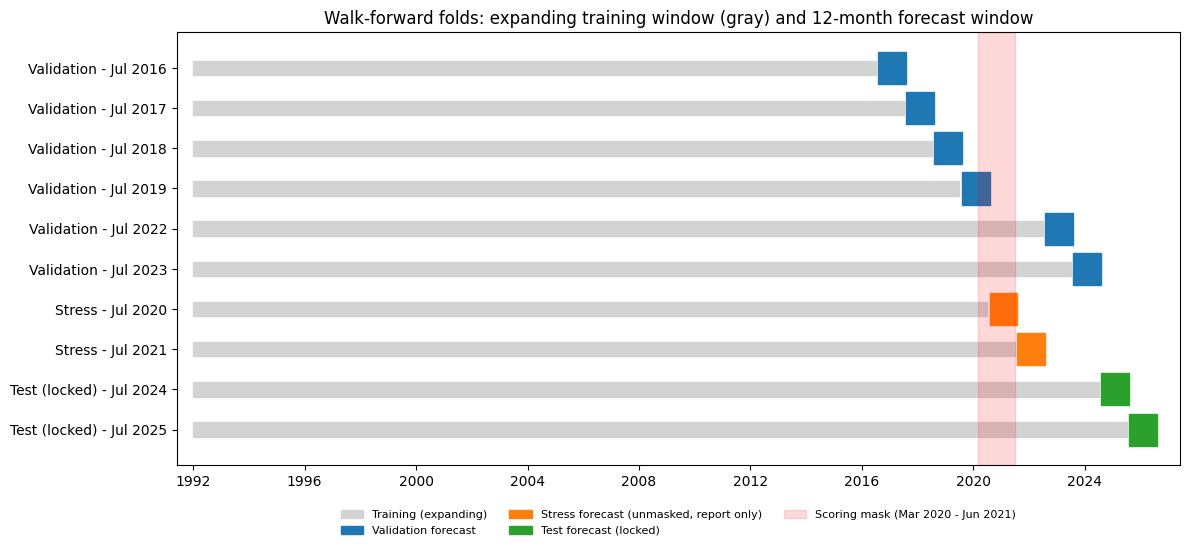

In [2]:
rows = ([("Validation", o, "tab:blue") for o in VALIDATION_ORIGINS]
        + [("Stress", o, "tab:orange") for o in STRESS_ORIGINS]
        + [("Test (locked)", o, "tab:green") for o in TEST_ORIGINS])

fig, ax = plt.subplots(figsize=(12, 5.6))
start_num = mdates.date2num(y.index.min())
for i, (group, origin, color) in enumerate(rows):
    fold = get_forecast_folds([origin], data_end=y.index.max())[0]
    train_end = mdates.date2num(fold["train_end"])
    f0 = mdates.date2num(fold["forecast_months"][0])
    f1 = mdates.date2num(fold["forecast_months"][-1] + pd.offsets.MonthEnd(0))
    ax.broken_barh([(start_num, train_end - start_num)], (i - 0.18, 0.36), color="lightgray")
    ax.broken_barh([(f0, f1 - f0)], (i - 0.4, 0.8), color=color)
ax.axvspan(mdates.date2num(MASK_START), mdates.date2num(MASK_END), color="red", alpha=0.15)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{g} - Jul {pd.Timestamp(o).year}" for g, o, _ in rows])
ax.invert_yaxis()
ax.xaxis_date()
ax.set_title("Walk-forward folds: expanding training window (gray) and 12-month forecast window")
ax.legend(handles=[Patch(color="lightgray", label="Training (expanding)"),
                   Patch(color="tab:blue", label="Validation forecast"),
                   Patch(color="tab:orange", label="Stress forecast (unmasked, report only)"),
                   Patch(color="tab:green", label="Test forecast (locked)"),
                   Patch(color="red", alpha=0.15, label="Scoring mask (Mar 2020 - Jun 2021)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, frameon=False)
ax.set_xlim(mdates.date2num(pd.Timestamp("1991-06-01")), mdates.date2num(pd.Timestamp("2027-06-01")))
fig.tight_layout()
(project_root / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(project_root / "reports" / "figures" / "split_diagram.png", dpi=150)
plt.show()

### Drift selection on the six validation folds

In [3]:
candidate_forecasters = {
    "Seasonal Naive": seasonal_naive_forecast,
    "Drift: masked mean YoY": make_drift_forecaster("mean_all"),
    "Drift: masked median YoY": make_drift_forecaster("median_all"),
    "Drift: trailing-12-month mean YoY": make_drift_forecaster("mean_trailing12"),
}
# evaluate() defaults to VALIDATION_ORIGINS and refuses the locked test origins.
validation_tables = {name: evaluate(fn, y) for name, fn in candidate_forecasters.items()}

drift_names = [n for n in candidate_forecasters if n != "Seasonal Naive"]
pooled_scores = {n: validation_tables[n]["MAE"].sum() / validation_tables[n]["Benchmark_SN_MAE"].sum() for n in drift_names}
best_drift_name = min(pooled_scores, key=pooled_scores.get)
print("Pooled RelMAE vs seasonal naive (six validation folds):")
print(pd.Series(pooled_scores, name="Pooled RelMAE").sort_values().round(3))
print(f"\nSelected drift baseline: {best_drift_name}")

# How many clean YoY observations feed each drift estimate, per fold?
rate_rows = []
for fold in get_forecast_folds(VALIDATION_ORIGINS, data_end=y.index.max()):
    train = y.loc[:fold["train_end"]]
    growth = eligible_yoy_growth(train)
    t_rate, t_n = trailing_growth(train)
    rate_rows.append({"Origin": f"{fold['origin']:%Y-%m}", "All_history_mean_%": growth.mean() * 100,
                      "All_history_median_%": growth.median() * 100, "Trailing12_%": t_rate * 100,
                      "Trailing12_n_obs": t_n, "Zero_drift_fallback": t_n < MIN_TRAILING_OBS})
rate_df = pd.DataFrame(rate_rows)
display(rate_df.round(2))
print(f"Folds using the zero-drift fallback: {int(rate_df['Zero_drift_fallback'].sum())}")

Pooled RelMAE vs seasonal naive (six validation folds):
Drift: trailing-12-month mean YoY    0.930
Drift: masked mean YoY               1.060
Drift: masked median YoY             1.132
Name: Pooled RelMAE, dtype: float64

Selected drift baseline: Drift: trailing-12-month mean YoY


,Origin,All_history_mean_%,All_history_median_%,Trailing12_%,Trailing12_n_obs,Zero_drift_fallback
0,2016-07,3.47,3.86,1.33,12,False
1,2017-07,3.37,3.72,0.87,12,False
2,2018-07,3.29,3.61,1.35,12,False
3,2019-07,3.19,3.40,0.77,12,False
4,2022-07,3.16,3.38,-2.39,1,True
5,2023-07,3.07,3.31,0.82,12,False


Folds using the zero-drift fallback: 1


In [4]:
sn_results = validation_tables["Seasonal Naive"]
drift_results = validation_tables[best_drift_name]

results_df = sn_results[["Origin", "Train_End", "Scored_Months", "MAE", "RMSE", "Bias", "December_Abs_Pct_Error"]].rename(columns={
    "MAE": "SN_MAE", "RMSE": "SN_RMSE", "Bias": "SN_Bias", "December_Abs_Pct_Error": "SN_Dec_Abs_Pct_Error"})
results_df["Drift_MAE"] = drift_results["MAE"].to_numpy()
results_df["Drift_RelMAE"] = drift_results["RelMAE_vs_SN"].to_numpy()
results_df["Drift_Dec_Abs_Pct_Error"] = drift_results["December_Abs_Pct_Error"].to_numpy()
display(results_df.round(3))

pooled_relmae = drift_results["MAE"].sum() / sn_results["MAE"].sum()
fold_wins = int((drift_results["RelMAE_vs_SN"] < 0.9999).sum())
fold_ties = int(np.isclose(drift_results["RelMAE_vs_SN"], 1.0).sum())
print(f"Pooled RelMAE for selected drift: {pooled_relmae:.3f}")
print(f"Folds beating seasonal naive: {fold_wins}/6 (ties: {fold_ties})")
print("Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds):", pooled_relmae <= 0.90 and fold_wins >= 4)

,Origin,Train_End,Scored_Months,SN_MAE,SN_RMSE,SN_Bias,SN_Dec_Abs_Pct_Error,Drift_MAE,Drift_RelMAE,Drift_Dec_Abs_Pct_Error
0,2016-07,2016-07,12,434.667,564.338,-217.500,3.557,387.981,0.893,2.279
1,2017-07,2017-07,12,590.667,718.648,-261.167,2.606,564.731,0.956,3.499
2,2018-07,2018-07,12,385.167,480.673,-157.833,0.351,425.031,1.103,0.995
3,2019-07,2019-07,7,601.571,709.364,-483.571,3.188,529.464,0.880,2.441
4,2022-07,2022-07,12,526.083,635.634,-142.250,1.165,526.083,1.000,1.165
5,2023-07,2023-07,12,668.000,807.580,-578.333,3.525,549.075,0.822,2.734


Pooled RelMAE for selected drift: 0.930
Folds beating seasonal naive: 4/6 (ties: 1)
Passes pre-declared bar (pooled <= 0.90 and >= 4/6 folds): False


### COVID stress folds (unmasked, report only)

In [5]:
for name in ["Seasonal Naive", best_drift_name]:
    print(name)
    display(evaluate(candidate_forecasters[name], y, STRESS_ORIGINS, mask=False).round(2))

Seasonal Naive


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7039.75,7039.75,9157.31,-3594.58,1.0,12.29
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.0,18.85


Drift: trailing-12-month mean YoY


,Origin,Train_End,Scored_Months,MAE,Benchmark_SN_MAE,RMSE,Bias,RelMAE_vs_SN,December_Abs_Pct_Error
0,2020-07,2020-07,12,7235.86,7039.75,9151.65,-3189.28,1.03,14.87
1,2021-07,2021-07,12,3269.17,3269.17,4077.56,-3146.67,1.00,18.85


## Findings & Interpretation

**Seasonal naive (the benchmark).** Bias is negative in all six validation folds (-578 to -142 $M per month), so it under-forecasts every time. MAE ranges 385–668 $M and RMSE 481–808 $M. The 2019 fold scores only 7 of 12 months because the mask removes March–July 2020.

**December.** Seasonal-naive December error is 0.35%–3.56% of December sales, the same order as a typical month. One December per fold is too little data to explain it, so no calendar or weekend explanation is claimed.

**Drift selection (six validation folds, fixed rule: lowest pooled RelMAE).** Pooled RelMAE vs. seasonal naive: masked mean YoY **1.060**, masked median YoY **1.132**, trailing-12-month mean YoY **0.930**. Only the trailing-12 estimator beats seasonal naive pooled, so it is the selected drift baseline.

**Why long-run drift fails.** Seasonal naive under-forecasts, but adding the average growth of the whole history over-corrects. The all-history estimators imply about 3.1%–3.9% a year, while the trailing-12 estimate at the five clean origins was only 0.8%–1.4%. Recent growth was slower than the historical average, so the estimate has to be recent.

**The selected drift, fold by fold.** RelMAE [0.89, 0.96, 1.1, 0.88, 1.0, 0.82]. It beats seasonal naive in 4 folds, ties in 1 (2022-07: only 1 clean YoY observation survived the mask, so the rule falls back to zero drift) and loses in 1 (2018-07). Pooled RelMAE is **0.930**, so it **does not pass** the pre-declared bar (pooled ≤ 0.90 and at least 4 of 6 folds). Seasonal naive stays the benchmark that Phase 4 models must beat; this drift (0.93) is the stronger reference to report against.

**COVID stress folds (unmasked, report only, never used for selection).** Seasonal naive MAE is 7,040 $M (Jul 2020 origin) and 3,269 $M (Jul 2021 origin), with December errors of 12.3% and 18.8%. Drift does not help (RelMAE 1.03 and 1.00). When the base year is COVID-distorted, repeating last year fails; Phase 4 models need the training-time COVID treatment.

**Limits.** Six folds are a small, noisy sample. The protocol assumes July sales are known at the end of July.


## Tests

The fold contract, the scoring mask, the training-data boundary, the test-set lock and the drift fallback are covered by `pytest` (tests live in `src/tests/`, run from the repository root with `pytest`).